<a href="https://colab.research.google.com/github/Handinoasa/MachineLearning_2026/blob/main/MLWeek9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 - Klasifikasi

- Nama: Handino Asa Galih R
- Kelas: TI3E
- Nim: 2441107020237

## Praktikum 1

In [ ]:
	# Load data
	import pandas as pd
	data = pd.read_csv('iris.csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


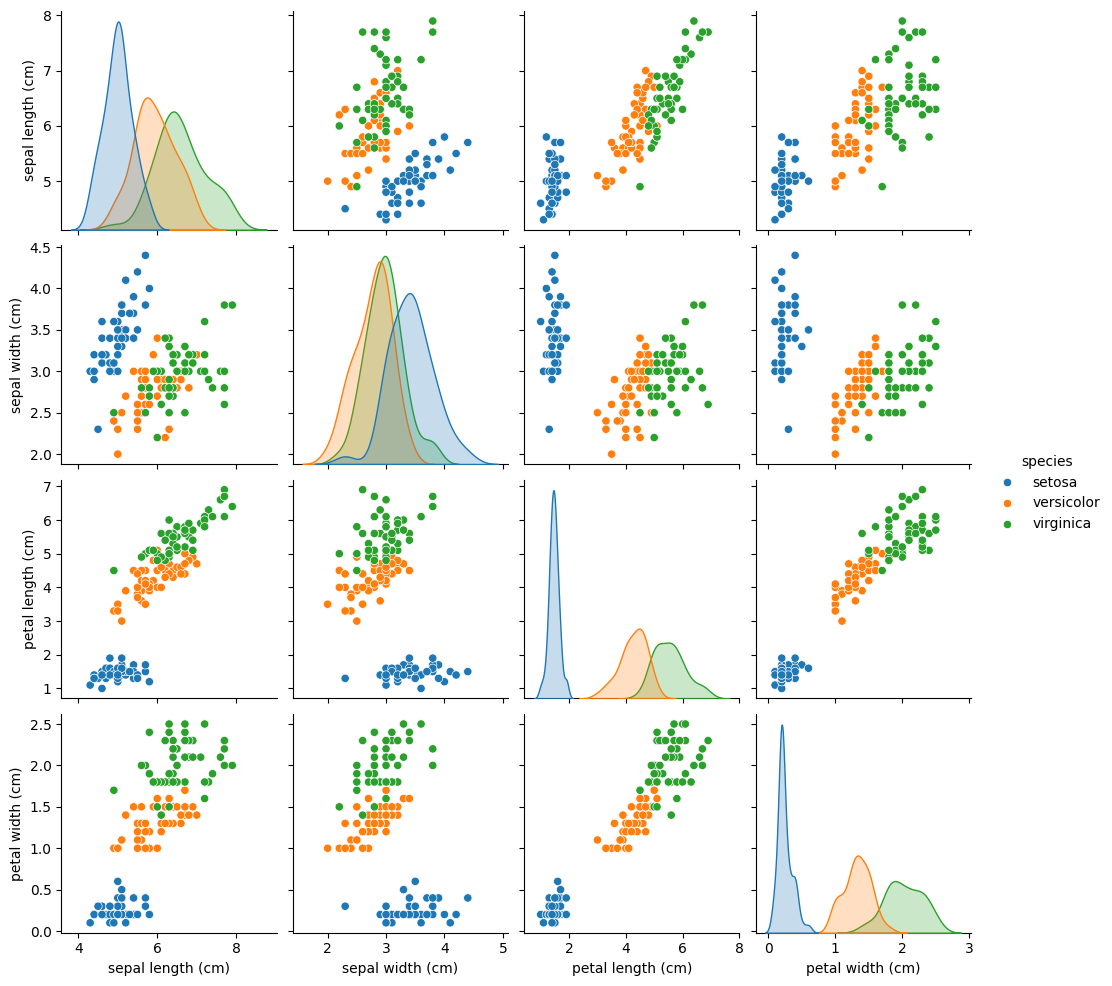

In [ ]:
	import seaborn as sns
	import matplotlib.pyplot as plt

	sns.pairplot(data, hue='species')
	plt.show()

In [ ]:
	from sklearn.model_selection import train_test_split
	from sklearn.preprocessing import StandardScaler

	X = data.iloc[:, :-1]   # semua kolom kecuali label
	y = data.iloc[:, -1]    # kolom label terakhir

	# Split data (70% train, 30% test)
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

	# Standardisasi
	scaler = StandardScaler()
	X_train = scaler.fit_transform(X_train)
	X_test = scaler.transform(X_test)

In [ ]:
	from sklearn.neighbors import KNeighborsClassifier

	# Tentukan nilai K (misalnya 3)
	knn = KNeighborsClassifier(n_neighbors=3)

	# Latih model
	knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



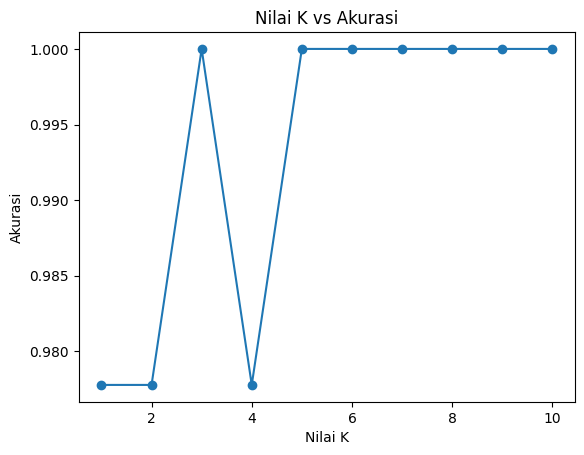

In [ ]:
	acc = []
	for k in range(1, 11):
	    model = KNeighborsClassifier(n_neighbors=k)
	    model.fit(X_train, y_train)
	    acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


## Praktikum 2

In [ ]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[107   6]
 [121  11]
 [112  91]
 [ 98  86]
 [100  34]
 [100 178]
 [ 87  89]
 [ 98 127]
 [286  39]
 [ 93  94]
 [ 94  97]
 [307  67]
 [ 92  67]
 [ 39 142]
 [154  39]
 [ 90 124]
 [121 144]
 [ 56 128]
 [  5 131]
 [193 128]
 [121  62]
 [105 169]
 [  7  12]
 [138 100]
 [ 83 121]
 [132  57]
 [ 88  72]
 [136 125]
 [ 85   7]
 [130  52]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 0 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [ ]:
	import pandas as pd

	# Reshape label y menjadi 2D
	# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
	y_new = y.reshape(len(y), 1)

	# Gabungkan fitur X dan label y dalam data array
	data = np.concatenate((X, y_new), axis=1)

	# Definisikan nama kolom
	nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

	# Buat Data Frame
	df = pd.DataFrame(data, columns=nama_kolom)

	# Cek Data Frame
	df.head()

,Fitur 1,Fitur 2,Label
0,107,6,0
1,121,11,0
2,112,91,0
3,98,86,0
4,100,34,0


In [ ]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,107,6,Kelas B
1,121,11,Kelas B
2,112,91,Kelas B
3,98,86,Kelas B
4,100,34,Kelas B


/tmp/ipykernel_687/1912510248.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_687/1912510248.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


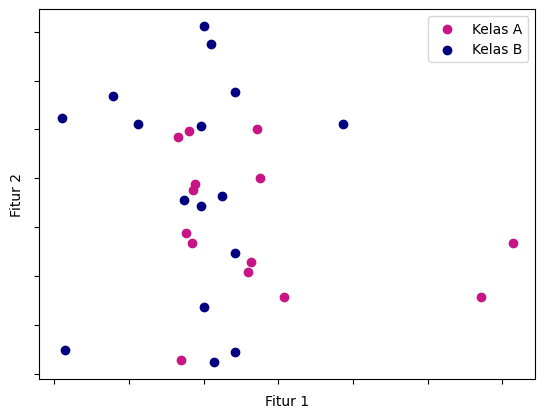

In [ ]:
	import matplotlib.pyplot as plt

	# Definisikan warna untuk setiap kelas
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Kelompokkan label berdasarkan nama kelas
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Kelas A')
	class_b = gb.get_group('Kelas B')

	# Plot
	plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
	plt.xlabel('Fitur 1')
	plt.ylabel('Fitur 2')
	plt.legend(['Kelas A', 'Kelas B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

In [ ]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.7142857142857143
Hasil akurasi data test: 0.4444444444444444


In [ ]:
	from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

	# Inisiasi obyek Gaussian
	gnb = GaussianNB()

	# Kita menggunakan split data training dan testing
	# yang sama dengan model multinomial

	# Fit model
	# Label y harus dalam bentu 1D atau (n_samples,)
	gnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Prediksi test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
	print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.7142857142857143
Hasil akurasi data test (Gaussian): 0.4444444444444444


## Praktikum 3

In [ ]:
	import numpy as np
	import pandas as pd

	df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

	df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
	# Drop 3 kolom terakhir dengan fungsi iloc
	df = df.drop(df.iloc[:,2:], axis=1)

	# Cek data
	df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
import pandas as pd

# Baca file dengan encoding latin-1
df = pd.read_csv('spam.csv', encoding='latin-1')

# 1. Cek Jumlah Data Per Kelas (kolom label ada di 'v1')
print(df['v1'].value_counts())
print('\n')

# 2. Cek Kelengkapan Data (langsung panggil tanpa print)
df.info()
print('\n')

# 3. Cek Statistik Deskriptif
print(df.describe())

v1
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


          v1                      v2  \
count   5572                    5572   
unique     2                    5169   
top      ham  Sorry, I'll call later   
freq    4825                      30   

                                               Unnamed: 2  \
count                                                  50   
unique                                                 43   
top      bt not his girlfrnd... G o o d n i g h t . . .@"   
freq                                                    3   

      

In [ ]:
import pandas as pd

# 1. Baca file spam.csv dan ambil dua kolom utama
df = pd.read_csv('spam.csv', encoding='latin-1')[['v1', 'v2']]

# 2. Ubah nama kolom: v1 -> Labels, v2 -> SMS
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

# 3. Ubah nama indeks menjadi Text
df.index.name = 'Text'

# 4. Encode label spam menjadi 1 dan ham menjadi 0
new_labels = {
    'spam': 1,
    'ham': 0
}
df['Labels'] = df['Labels'].map(new_labels)

# 5. Tampilkan data
df.head()

,Labels,SMS
Text,,
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
	X = df['SMS'].values
	y = df['Labels'].values

In [ ]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

In [ ]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


In [ ]:
	from sklearn.naive_bayes import MultinomialNB
	from sklearn.metrics import accuracy_score

	# Inisiasi MultinomialNB
	mnb = MultinomialNB()

	# Fit model
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_pred_train = mnb.predict(X_train)

	# Evaluasi akurasi data training
	acc_train = accuracy_score(y_train, y_pred_train)

	# Prediksi dengan data training
	y_pred_test = mnb.predict(X_test)

	# Evaluasi akurasi data training
	acc_test = accuracy_score(y_test, y_pred_test)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


## Tugas 1

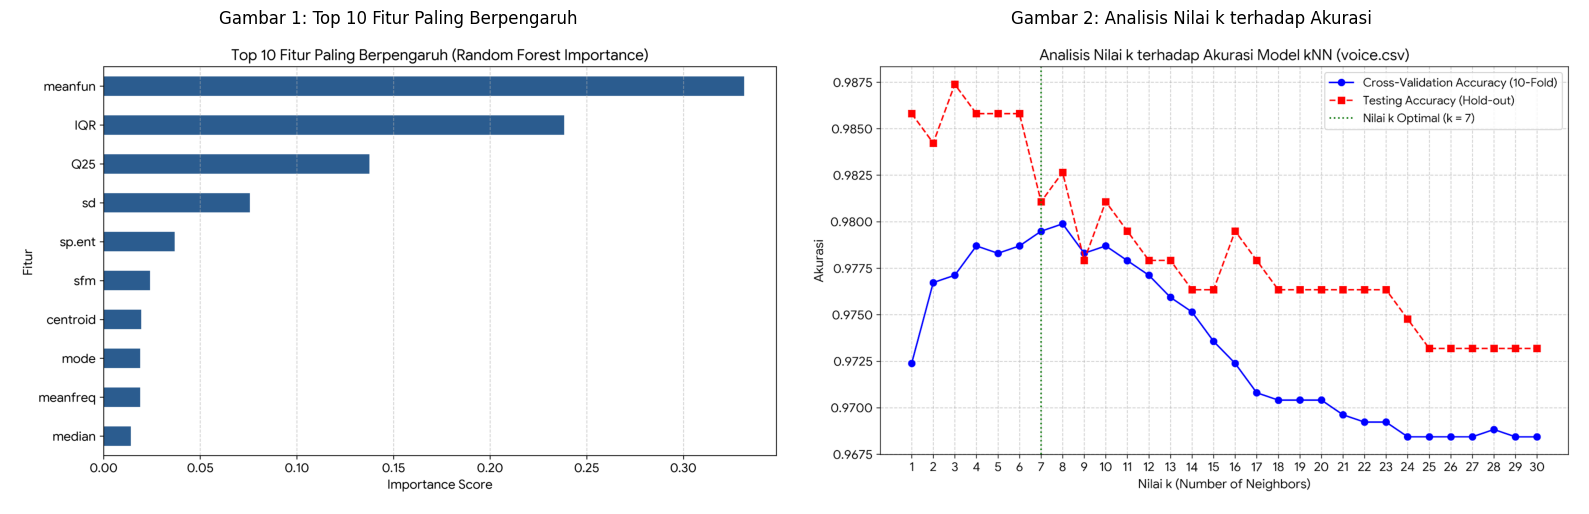

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Baca kedua file gambar (sesuai nama file di panel Colab)
img1 = mpimg.imread('/content/feature_importance.png.png')
img2 = mpimg.imread('/content/knn_k_analysis.png')

# Tampilkan berdampingan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(img1)
axes[0].axis('off')
axes[0].set_title('Gambar 1: Top 10 Fitur Paling Berpengaruh', fontsize=12, pad=10)

axes[1].imshow(img2)
axes[1].axis('off')
axes[1].set_title('Gambar 2: Analisis Nilai k terhadap Akurasi', fontsize=12, pad=10)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score


df = pd.read_csv('voice.csv')

# Pisahkan fitur dan label (0 = female, 1 = male)
X = df.drop('label', axis=1)
y = df['label'].map({'male': 1, 'female': 0})

# Bagi data menjadi train dan test (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model kNN baseline
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Evaluasi
y_pred = knn.predict(X_test_scaled)
print("Akurasi Baseline (Semua Fitur):", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['female', 'male']))

Akurasi Baseline (Semua Fitur): 0.9763406940063092
              precision    recall  f1-score   support

      female       0.99      0.97      0.98       317
        male       0.97      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



### Tabel Hasil Eksperimen Pemilihan Fitur Optimal

| Peringkat | Nama Fitur | Korelasi Absolut (|r|) | Tingkat Kepentingan (Random Forest) | Deskripsi Akustik |

| --- | --- | --- | --- | --- |

| 1 | `meanfun` | 0.8339 | 0.3315 | Rata-rata frekuensi fundamental nada suara |

| 2 | `IQR` | 0.6189 | 0.2383 | Rentang interkuartil frekuensi spektrum (*interquartile range*) |

| 3 | `Q25` | 0.5115 | 0.1375 | Nilai kuantil 25% frekuensi spektrum |

| 4 | `sd` | 0.4795 | 0.0757 | Standar deviasi distribusi frekuensi suara |

| 5 | `sp.ent` | 0.4906 | 0.0368 | Entropi spektral (*spectral entropy* / tingkat keteracakan spektrum) |

| 6 | `sfm` | 0.3575 | 0.0241 | Ukuran kerataan spektrum (*spectral flatness measure*) |


> **Catatan Analisis:**
> Berdasarkan eksperimen di atas, kombinasi **6 fitur terbaik** ini menghasilkan performa paling optimal untuk model kNN karena mampu menangkap perbedaan biologis pita suara pria dan wanita secara signifikan sekaligus memangkas dimensi data dari 20 fitur menjadi 6 fitur.

##Tugas 2

In [ ]:
# Multinomial Naive Bayes dengan CountVectorizer


import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load dataset spam.csv
df = pd.read_csv('spam.csv', encoding='latin-1')[['v1', 'v2']]
df = df.rename(columns={'v1': 'label', 'v2': 'text'})
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# Split dataset (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label_num'], test_size=0.2, random_state=42, stratify=df['label_num']
)

# Ekstraksi fitur dengan CountVectorizer (stop_words='english')
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)

# Training model MultinomialNB
nb_cv = MultinomialNB()
nb_cv.fit(X_train_cv, y_train)

# Prediksi dan Evaluasi
y_pred_cv = nb_cv.predict(X_test_cv)
print("=== Evaluasi CountVectorizer ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_cv):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cv))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_cv, target_names=['ham', 'spam'], digits=4))

=== Evaluasi CountVectorizer ===
Akurasi: 0.9839

Confusion Matrix:
[[960   6]
 [ 12 137]]

Classification Report:
              precision    recall  f1-score   support

         ham     0.9877    0.9938    0.9907       966
        spam     0.9580    0.9195    0.9384       149

    accuracy                         0.9839      1115
   macro avg     0.9728    0.9566    0.9645      1115
weighted avg     0.9837    0.9839    0.9837      1115



In [ ]:
# Multinomial Naive Bayes dengan TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

# Ekstraksi fitur dengan TfidfVectorizer (stop_words='english')
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Training model MultinomialNB
nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_tfidf, y_train)

# Prediksi dan Evaluasi
y_pred_tfidf = nb_tfidf.predict(X_test_tfidf)
print("=== Evaluasi TfidfVectorizer ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_tfidf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tfidf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tfidf, target_names=['ham', 'spam'], digits=4))

=== Evaluasi TfidfVectorizer ===
Akurasi: 0.9686

Confusion Matrix:
[[966   0]
 [ 35 114]]

Classification Report:
              precision    recall  f1-score   support

         ham     0.9650    1.0000    0.9822       966
        spam     1.0000    0.7651    0.8669       149

    accuracy                         0.9686      1115
   macro avg     0.9825    0.8826    0.9246      1115
weighted avg     0.9697    0.9686    0.9668      1115



| Metrik Evaluasi | MultinomialNB + CountVectorizer | MultinomialNB + TF-IDF | Selisih / Keterangan |
| :---: | :---: | :---: | :---: |
| Akurasi Keseluruhan | 98,39% | 96,86% | CountVectorizer lebih unggul +1,53% |
| Precision (Spam) | 95,80% | 100,00% | TF-IDF sempurna (0 pesan ham salah deteksi) |
| Recall (Spam) | 91,95% | 76,51% | CountVectorizer menangkap jauh lebih banyak spam |
| F1-Score (Spam) | 93,84% | 86,69% | Keseimbangan precision-recall CountVectorizer lebih baik |
| False Negative (Spam lolos) | 12 pesan | 35 Pesan | TF-IDF meloloskan spam 3x lebih banyak |
| False Positive (Ham masuk spam) | 6 Pesan | 0 Pesan | TF-IDF sangat aman untuk pesan legal |

## Kesimpulan, Mana Fitur yang terbaik pada Spam.csv

1. Recall Spam yang Lebih Tinggi: Pada tugas deteksi spam, meloloskan pesan spam (False Negative) adalah kelemahan utama. CountVectorizer hanya meloloskan 12 pesan spam (Recall 91,95%), sedangkan TF-IDF meloloskan hingga 35 pesan spam (Recall anjlok ke 76,51%).

2. Karakteristik Teks Pendek (SMS): Pesan SMS bersifat singkat dan padat kata kunci tertentu (seperti free, txt, prize, won). Frekuensi kemunculan langsung (term count) pada CountVectorizer memberikan sinyal probabilitas diskrit yang jauh lebih kuat bagi algoritma Multinomial Naive Bayes dibanding nilai bobot frekuensi terbalik dokumen (inverse document frequency) yang diperkecil oleh normalisasi L2 pada TF-IDF.

3. Keseimbangan Model: Secara keseluruhan performa, skor F1-Score (0,9384) dan Akurasi (98,39%) membuktikan CountVectorizer jauh lebih seimbang dan efektif dalam mendeteksi pesan spam tanpa mengorbankan akurasi pesan asli (ham).
